# Predicción de solicitudes de retiro total de aportes sociales — Confiar

**Reporte de selección de modelo**

| | |
|---|---|
| **Grupo** | Carlos Galvis · Jaqueline Acevedo |
| **Tipo de problema** | Clasificación binaria |
| **Dataset** | `bd_confiar_2.xlsx` — 194.073 registros, 25 columnas |
| **Variable objetivo** | `sol_retiro` (1 = radicó solicitud de retiro total) |

## 1. Introducción

Para Confiar, la actividad financiera es el medio que le permite contribuir al Bienvivir de sus
miembros y de los territorios donde estos se localizan. El fundamento de esa relación es el
**vínculo asociativo**, cuya manifestación concreta son los **aportes sociales**: las
contribuciones económicas de quienes deciden, libre y voluntariamente, incorporarse a la
cooperativa en calidad de asociados.

Las tasas de abandono (*churn*) anual muestran una estabilización en el retiro de asociados y de
saldos de aportes en los últimos tres años. Aun así, la cooperativa busca alternativas para
mejorar ese indicador. Siguiendo la clasificación de Lozano (2014), el churn en Confiar puede
mirarse desde dos perspectivas:

- **La magnitud de la ruptura:** retiro parcial o total de saldos de aportes.
- **La voluntad del asociado:** la persona puede retirarse por voluntad propia, o la cooperativa
  puede actuar unilateralmente (cruces de cuentas o de cartera, incorrección, voluntad de los
  herederos en caso de fallecimiento).

Este trabajo se concentra en el cruce más relevante para la gestión: **el retiro total radicado
por voluntad del asociado**, que es el único sobre el cual la cooperativa puede intervenir
anticipadamente.

### Cómo se construyó el dataset

Se partió de datos tipo panel de corte mensual (variables sociodemográficas, financieras,
relacionales y transaccionales) de asociados vinculados entre 2017 y 2025. La transformación a
un registro por asociado siguió dos antecedentes:

- **Fajardo y Motta (2019)**, que usan el registro más reciente de cada cliente para construir un
  dataset de usuarios. Aquí: para quien radica solicitud, el registro es el del mes de la
  radicación; para quien no radica, el del último periodo transcurrido sin radicar.
- **Raza, Manoj, Singh y Blumenstock (2015)**, que construyen variables calculadas resumiendo el
  comportamiento durante un periodo: promedios mensuales, porcentajes de actividad y razones
  entre valores mínimos y máximos.

El resultado es `bd_confiar_2.xlsx`: 194.073 registros, uno por asociado, ya tratado en nulos,
atípicos y escala de las variables financieras.

## 2. Objetivo

> Predecir qué asociados tienen alta probabilidad de radicar una solicitud de retiro total, con
> suficiente anticipación para intervenir, e identificar qué factores se asocian a su permanencia.

**Por qué un modelo y no una regla.** La cooperativa podría ordenar a los asociados por un solo
criterio (antigüedad, saldo, inactividad) y atender a los peores. El modelo combina veintiún
señales a la vez y entrega una probabilidad por asociado, lo que permite priorizar bajo una
restricción de capacidad —cuántas personas alcanza a contactar el equipo— en lugar de aplicar un
corte arbitrario.

## 3. Instrumentos

**Librerías:** pandas, NumPy, Matplotlib, Seaborn, scikit-learn, SHAP.

**Modelos evaluados:** Baseline (clase mayoritaria), Regresión Logística, Árbol de Decisión,
Random Forest, K-Vecinos y Gradient Boosting.

## 4. Ruta del proyecto

```
Datos → Partición (fit / valid / test) → Torneo con validación cruzada sobre fit
      → Lectura del torneo contra el ruido entre folds → Elección del modelo
      → Punto de operación (umbral) elegido sobre valid
      → Evaluación final sobre test, una sola vez → Explicabilidad → Conclusiones
```

**Regla que gobierna todo el cuaderno:** el conjunto de prueba no participa en ninguna decisión.
No entrena, no selecciona modelo, no fija el umbral. Se abre una vez, al final.

## 5. Configuración

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score,
                             classification_report, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
N_SPLITS = 5

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})

VERDE, AGUA, GRIS, NARANJA, ROJO = "#406965", "#49ACA3", "#94A3B8", "#E08A3C", "#C0392B"

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 6. Datos

### 6.1 Carga y ajustes

In [2]:
retiro = pd.read_excel("bd_confiar_2.xlsx")
print(f"archivo original : {retiro.shape[0]:,} registros x {retiro.shape[1]} columnas")

# Tres columnas no entran al modelado:
#   Nit               -> identificador; un modelo solo podría memorizarlo
#   anio_mes_proceso  -> fecha del corte, distinta para cada asociado
#   cohorte           -> fecha de vinculación; su información ya está en antig_meses
retiro = retiro.drop(columns=["Nit", "anio_mes_proceso", "cohorte"])

n_antes = len(retiro)
retiro = retiro.drop_duplicates()
print(f"filas idénticas eliminadas : {n_antes - len(retiro):,}")
print(f"dataset de trabajo         : {retiro.shape[0]:,} registros x {retiro.shape[1]} columnas")

archivo original : 194,073 registros x 25 columnas
filas idénticas eliminadas : 163
dataset de trabajo         : 193,910 registros x 22 columnas


**Por qué se eliminan las filas idénticas.** Al quitar el identificador, algunos registros quedan
con exactamente los mismos veintidós valores. Pueden corresponder a personas distintas, pero para
el modelo son indistinguibles, y si una copia cae en entrenamiento y otra en prueba el modelo
estaría siendo evaluado sobre una fila que ya vio. Eliminarlas protege la honestidad de la
evaluación. Son 163 registros sobre 194.073: menos del 0,1 %.

In [3]:
diagnostico = pd.DataFrame({
    "tipo": retiro.dtypes.astype(str),
    "nulos": retiro.isna().sum(),
    "distintos": retiro.nunique(),
    "media": retiro.mean().round(2),
    "mediana": retiro.median().round(2),
    "max": retiro.max().round(2),
    "sesgo": retiro.skew().round(2),
})
diagnostico

,tipo,nulos,distintos,media,mediana,max,sesgo
saldo_aportes,float64,0,97033,1.18,0.54,52.88,3.54
prom_saldo_capitalizacion_aportes,float64,0,131768,0.05,0.02,11.39,15.65
porc_meses_capitaliza_aportes,float64,0,3562,0.36,0.25,1.00,0.64
antig_meses,int64,0,108,39.93,35.00,107.00,0.53
sol_retiro,int64,0,2,0.21,0.00,1.00,1.43
saldo_ahorro_prog,float64,0,37523,0.74,0.00,30.00,6.57
prom_saldo_ahorro_prog,float64,0,93360,0.94,0.00,27.90,5.88
rel_min-max_ahorro_prog,float64,0,30027,0.07,0.00,1.00,3.30
saldo_cta,float64,0,28653,0.21,0.00,35.00,13.79
prom_saldo_cta,float64,0,106014,0.23,0.00,10.00,7.24


Todas las columnas son numéricas y no hay nulos: el tratamiento previo de valores faltantes,
atípicos y escala ya fue aplicado sobre los datos de origen.

Lo que sí conviene señalar es el **sesgo**. Varias variables financieras tienen colas muy largas
(`prom_saldo_cartera`, `prom_trx`, `saldo_ahorro_prog`): la mediana está en cero o cerca, y el
máximo está a cientos de desviaciones. Esto tiene una consecuencia concreta en el torneo: los
modelos basados en distancias (K-Vecinos) y los lineales son sensibles a esa escala, mientras que
los basados en árboles son indiferentes. Por eso **todos los modelos se estandarizan por igual**
(sección 8), para que ninguno compita en mejores condiciones que otro.

### 6.2 La variable objetivo

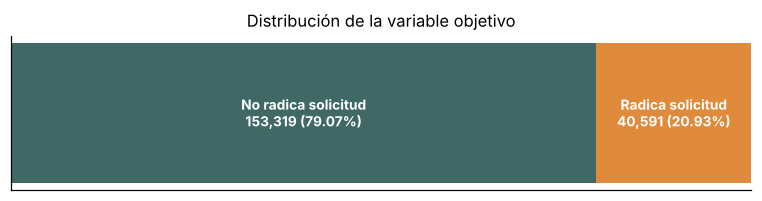

Tasa base: 20.93% de los asociados radicó solicitud de retiro total.


In [4]:
conteo = retiro["sol_retiro"].value_counts().sort_index()
tasa_base = retiro["sol_retiro"].mean()

fig, ax = plt.subplots(figsize=(7, 1.9))
izq = 0
for valor, etiqueta, color in [(0, "No radica solicitud", VERDE), (1, "Radica solicitud", NARANJA)]:
    ancho = conteo[valor] / conteo.sum()
    ax.barh(0, ancho, left=izq, color=color, height=.5)
    ax.text(izq + ancho / 2, 0, f"{etiqueta}\n{conteo[valor]:,} ({ancho:.2%})",
            ha="center", va="center", color="white", fontsize=9, weight="bold")
    izq += ancho
ax.set_xlim(0, 1); ax.set_yticks([]); ax.set_xticks([]); ax.grid(False)
ax.set_title("Distribución de la variable objetivo")
plt.tight_layout(); plt.show()

print(f"Tasa base: {tasa_base:.2%} de los asociados radicó solicitud de retiro total.")

**Cómo leer este número, y por qué importa desde ya.**

El 20,9 % de los asociados radicó solicitud. Eso significa que **un modelo que no aprenda nada y
responda siempre "no radica" acierta el 79,1 % de las veces**. Ese es el piso contra el cual hay
que comparar cualquier resultado, y es la razón por la que la exactitud (*accuracy*) no se usa
como criterio en este trabajo: es la métrica que mejor premia a ese modelo inútil.

A esta desproporción se le llama **desbalance de clases**. A 79/21 es moderado —no es el caso
extremo del fraude, donde la clase positiva es 1 de cada 500— pero sí suficiente para que los
modelos, buscando minimizar el error total, se inclinen hacia la clase mayoritaria.

In [5]:
# ¿En qué se diferencian quienes radican de quienes no?
perfil = retiro.groupby("sol_retiro").mean().T
perfil.columns = ["No radica", "Radica"]
perfil["diferencia %"] = ((perfil["Radica"] - perfil["No radica"]) /
                          perfil["No radica"].replace(0, np.nan) * 100).round(1)
perfil.round(3).sort_values("diferencia %", key=abs, ascending=False)

,No radica,Radica,diferencia %
rel_min-max_saldo_cartera,0.098,0.003,-97.0
saldo_cta,0.247,0.089,-64.1
rel_min-max_ahorro_prog,0.086,0.031,-63.4
porc_meses_publiturno,0.173,0.262,51.1
rel_min-max_saldo_cta,0.056,0.028,-49.4
saldo_ahorro_prog,0.828,0.420,-49.3
prom_asesorias_publiturno,0.360,0.526,46.3
prom_saldo_cartera,5.038,2.881,-42.8
porc_meses_capitaliza_aportes,0.332,0.472,42.1
antig_meses,41.778,32.959,-21.1


## 7. Partición del dataset

In [6]:
X = retiro.drop(columns="sol_retiro")
y = retiro["sol_retiro"]

# 80% fit  |  10% valid  |  10% test   (estratificado en los dos cortes)
X_fit, X_temp, y_fit, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp)

particion = pd.DataFrame({
    "conjunto": ["fit", "valid", "test"],
    "registros": [len(X_fit), len(X_valid), len(X_test)],
    "% del total": [len(X_fit) / len(X), len(X_valid) / len(X), len(X_test) / len(X)],
    "tasa de radicación": [y_fit.mean(), y_valid.mean(), y_test.mean()],
    "para qué sirve": ["entrenar y validar modelos (CV)",
                       "elegir el punto de operación",
                       "reportar el resultado final, una vez"],
})
particion.style.format({"registros": "{:,}", "% del total": "{:.1%}",
                        "tasa de radicación": "{:.4f}"}).hide(axis="index")

conjunto,registros,% del total,tasa de radicación,para qué sirve
fit,"155,128",80.0%,0.2093,entrenar y validar modelos (CV)
valid,"19,391",10.0%,0.2093,elegir el punto de operación
test,"19,391",10.0%,0.2093,"reportar el resultado final, una vez"


Las tres tasas de radicación coinciden hasta el cuarto decimal: la estratificación funcionó y los
tres conjuntos son comparables entre sí.

**Para qué sirve cada uno.** La separación en tres no es un capricho: cada decisión que se tome
mirando unos datos "gasta" esos datos. El conjunto de entrenamiento ajusta los modelos; el de
validación elige entre ellos y fija el umbral; el de prueba no participa en ninguna decisión y por
eso puede medir, al final, lo que el modelo hará con asociados que nunca vio.

## 8. Preparativos del torneo

### 8.1 Los competidores

In [7]:
# Todos los modelos reciben EXACTAMENTE el mismo trato:
#   - el mismo pipeline, con StandardScaler
#   - ningún ajuste de desbalance (ni class_weight ni remuestreo)
# El desbalance se aborda después, en la sección 10, con el umbral.
def construir(modelo):
    return Pipeline([("escalar", StandardScaler()), ("modelo", modelo)])

modelos = {
    "Baseline (clase mayoritaria)": DummyClassifier(strategy="most_frequent"),
    "Regresión Logística":          LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "Árbol de Decisión":            DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest":                RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "K-Vecinos":                    KNeighborsClassifier(n_jobs=-1),
    "Gradient Boosting":            GradientBoostingClassifier(random_state=RANDOM_STATE),
}
for nombre in modelos:
    print(f"  • {nombre}")

  • Baseline (clase mayoritaria)
  • Regresión Logística
  • Árbol de Decisión
  • Random Forest
  • K-Vecinos
  • Gradient Boosting


**Dos decisiones de diseño, y por qué.**

**El baseline no compite: sirve de referencia.** `DummyClassifier(strategy="most_frequent")`
responde siempre "no radica", sin mirar ninguna variable. No es un predictor aleatorio —es un
predictor constante— y su función es dar la medida de cuánto aporta modelar frente a no modelar.
Sin él, un 0,79 de exactitud parecería un buen resultado.

**Ningún modelo recibe tratamiento del desbalance.** Ni `class_weight`, ni remuestreo. La razón es
que ese ajuste no mejora la capacidad de un modelo: mueve su punto de operación, favoreciendo el
recall a costa de la precisión. Si unos modelos lo tuvieran y otros no, el torneo compararía
puntos de operación distintos en lugar de modelos. El desbalance se aborda en la sección 10, de
forma explícita y para el modelo ya elegido.

### 8.2 Qué vamos a medir, y por qué

La decisión que alimenta este modelo es a qué asociados dirigir una acción de retención antes de
que radiquen. Los dos errores posibles cuestan cosas muy distintas:

| Resultado | Qué significa | Qué cuesta |
|---|---|---|
| **Verdadero positivo (VP)** | iba a radicar y el modelo lo detecta | nada: es el acierto que buscamos |
| **Falso positivo (FP)** | no iba a radicar y el modelo lo marca | una comunicación, un souvenir, una llamada |
| **Falso negativo (FN)** | iba a radicar y el modelo no lo ve | **el retiro total de los aportes de ese asociado** |
| **Verdadero negativo (VN)** | no iba a radicar y el modelo no lo marca | nada |

**El objetivo es maximizar los verdaderos positivos**, aun a costa de aceptar falsos positivos. Un
falso positivo cuesta el precio de una acción de fidelización —que además refuerza el vínculo
asociativo, de modo que ni siquiera es puro desperdicio—. Un falso negativo cuesta un asociado y
el saldo completo de sus aportes. **La asimetría es de varios órdenes de magnitud.**

De ahí se desprenden las métricas:

| Métrica | Qué responde | Por qué se incluye |
|---|---|---|
| **AUC-ROC** | ¿ordena bien a los asociados, de más a menos riesgo? | resume la capacidad del modelo sin depender del umbral; sirve para comparar en el torneo |
| **Recall de la clase 1** | de quienes radicaron, ¿a cuántos detectó? | mide la **oportunidad perdida**: es la métrica alineada con el costo real |
| **Precisión de la clase 1** | de los marcados, ¿cuántos iban a radicar? | mide el **esfuerzo desperdiciado**; se reporta para dimensionar el costo operativo |
| **F1 de la clase 1** | equilibrio entre las dos | resumen, siempre leído junto a las dos anteriores |
| **Promedio de precisión (AP)** | área bajo la curva precisión–recall | más informativa que el AUC cuando la clase positiva es minoritaria |

**La exactitud (*accuracy*) se excluye deliberadamente.** Con una clase mayoritaria del 79 %, es la
métrica que premia al modelo que nunca detecta a nadie.

> **Y una regla que vamos a aplicar en todo el cuaderno:** cada vez que comparemos dos números
> obtenidos por validación cruzada, diremos si la diferencia es mayor o menor que la **variación
> esperada entre folds**. Una diferencia más pequeña que esa variación no es un hallazgo.

## 9. El torneo

In [8]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

METRICAS = {"auc": "roc_auc", "ap": "average_precision",
            "recall_1": "recall", "precision_1": "precision", "f1_1": "f1"}

filas = []
for nombre, modelo in modelos.items():
    # cross_validate ajusta el escalador DENTRO de cada fold, solo con sus datos de
    # entrenamiento. Ni el fold de validación ni test participan en ese ajuste.
    cvres = cross_validate(construir(modelo), X_fit, y_fit, cv=cv,
                           scoring=METRICAS, n_jobs=1)
    fila = {"modelo": nombre}
    for clave in METRICAS:
        fila[clave] = cvres[f"test_{clave}"].mean()
        fila[f"{clave}_sd"] = cvres[f"test_{clave}"].std()
    filas.append(fila)
    print(f"  ✓ {nombre}")

torneo = pd.DataFrame(filas).sort_values("auc", ascending=False).reset_index(drop=True)

  ✓ Baseline (clase mayoritaria)


  ✓ Regresión Logística


  ✓ Árbol de Decisión


  ✓ Random Forest


  ✓ K-Vecinos


  ✓ Gradient Boosting


In [9]:
columnas = ["modelo", "auc", "auc_sd", "ap", "recall_1", "recall_1_sd",
            "precision_1", "precision_1_sd", "f1_1", "f1_1_sd"]
torneo[columnas].round(4)

,modelo,auc,auc_sd,ap,recall_1,recall_1_sd,precision_1,precision_1_sd,f1_1,f1_1_sd
0,Random Forest,0.8948,0.0016,0.7036,0.5009,0.0049,0.7499,0.0058,0.6006,0.0052
1,Gradient Boosting,0.8872,0.0018,0.6826,0.4639,0.0070,0.7294,0.0055,0.5671,0.0066
2,Regresión Logística,0.7873,0.0022,0.4525,0.1761,0.0044,0.5508,0.0071,0.2668,0.0056
3,K-Vecinos,0.7797,0.0025,0.4526,0.4333,0.0046,0.5306,0.0046,0.4771,0.0043
4,Árbol de Decisión,0.6972,0.0032,0.3695,0.5263,0.0052,0.5136,0.0063,0.5199,0.0051
5,Baseline (clase mayoritaria),0.5000,0.0000,0.2093,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


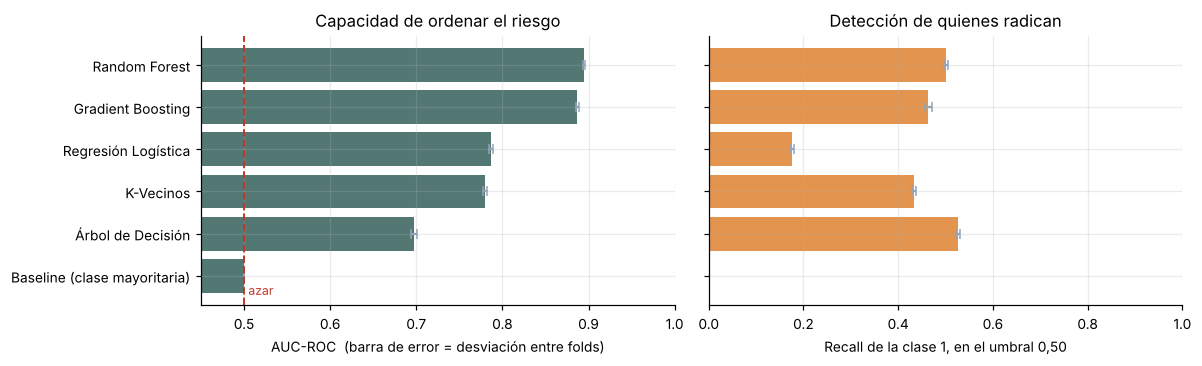

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

t = torneo.iloc[::-1]
axes[0].barh(t["modelo"], t["auc"], xerr=t["auc_sd"], color=VERDE, alpha=.9,
             error_kw={"ecolor": GRIS, "capsize": 3})
axes[0].axvline(0.5, color=ROJO, ls="--", lw=1.3)
axes[0].text(0.505, -0.45, "azar", color=ROJO, fontsize=8)
axes[0].set_xlim(0.45, 1.0)
axes[0].set_xlabel("AUC-ROC  (barra de error = desviación entre folds)")
axes[0].set_title("Capacidad de ordenar el riesgo")

axes[1].barh(t["modelo"], t["recall_1"], xerr=t["recall_1_sd"], color=NARANJA, alpha=.9,
             error_kw={"ecolor": GRIS, "capsize": 3})
axes[1].set_xlim(0, 1)
axes[1].set_xlabel("Recall de la clase 1, en el umbral 0,50")
axes[1].set_title("Detección de quienes radican")
axes[1].set_yticklabels([])

plt.tight_layout(); plt.show()

### 9.1 Lectura del torneo contra la variación entre folds

In [11]:
# ¿Qué diferencias son reales y cuáles caben dentro del ruido?
reales = torneo[torneo["modelo"] != "Baseline (clase mayoritaria)"].reset_index(drop=True)
lider = reales.iloc[0]

comparacion = pd.DataFrame({
    "modelo": reales["modelo"],
    "AUC": reales["auc"].round(4),
    "diferencia vs. líder": (lider["auc"] - reales["auc"]).round(4),
    "ruido típico (sd del líder)": lider["auc_sd"].round(4),
    "¿la diferencia supera el ruido?": np.where(
        (lider["auc"] - reales["auc"]) > lider["auc_sd"], "sí", "no — empatan"),
})
comparacion

,modelo,AUC,diferencia vs. líder,ruido típico (sd del líder),¿la diferencia supera el ruido?
0,Random Forest,0.8948,0.0000,0.0016,no — empatan
1,Gradient Boosting,0.8872,0.0076,0.0016,sí
2,Regresión Logística,0.7873,0.1076,0.0016,sí
3,K-Vecinos,0.7797,0.1151,0.0016,sí
4,Árbol de Decisión,0.6972,0.1977,0.0016,sí


In [12]:
base = torneo[torneo["modelo"] == "Baseline (clase mayoritaria)"].iloc[0]
print("EL BASELINE, QUE ES LA MEDIDA DE CUÁNTO APORTA MODELAR")
print(f"  AUC          : {base['auc']:.4f}   (0,50 = no distingue a nadie)")
print(f"  Recall clase 1: {base['recall_1']:.4f}   (no detecta ni un solo caso)")
print(f"  Precisión     : {base['precision_1']:.4f}")
print()
print(f"El mejor modelo del torneo alcanza AUC {lider['auc']:.4f}:")
print(f"  {lider['auc'] - base['auc']:.4f} por encima del baseline, "
      f"es decir {(lider['auc'] - base['auc']) / lider['auc_sd']:.0f} veces el ruido entre folds.")

EL BASELINE, QUE ES LA MEDIDA DE CUÁNTO APORTA MODELAR
  AUC          : 0.5000   (0,50 = no distingue a nadie)
  Recall clase 1: 0.0000   (no detecta ni un solo caso)
  Precisión     : 0.0000

El mejor modelo del torneo alcanza AUC 0.8948:
  0.3948 por encima del baseline, es decir 248 veces el ruido entre folds.


**Qué dice el torneo.**

**Modelar aporta, y mucho.** El baseline obtiene AUC 0,5000 y recall 0,0000: no detecta ni a un
solo asociado de los que radican. El mejor modelo llega a 0,8948, es decir **248 veces la
variación entre folds** por encima de ese piso. La pregunta de si vale la pena modelar queda
contestada con un margen que no admite discusión.

**Entre los modelos reales sí hay diferencias, y son reales.** Random Forest y Gradient Boosting
se separan del resto por más de 0,10 de AUC, contra una variación entre folds de apenas 0,0016:
la distancia es **sesenta veces el ruido**. Esto no es un empate como los que suelen aparecer en
estas comparaciones; es una diferencia sólida.

**La única pareja que empata es la cabeza.** Random Forest (0,8948) y Gradient Boosting (0,8872)
están separados por 0,0076, apenas cuatro veces el ruido — una diferencia real pero modesta, y
que en todo caso no cambia la conclusión.

**El dato que más conviene mirar es el AP**, no el AUC. Con una clase positiva del 20,9 %, el
promedio de precisión describe mejor cuánto vale la lista que se va a accionar: Random Forest
obtiene 0,7036 contra 0,4525 de la Regresión Logística. Esa brecha es mucho más grande que la que
sugiere el AUC, y es la que hay que tener presente en la sección siguiente.

**Sobre el recall de la tabla.** Los valores de recall de esta tabla están medidos en el umbral
0,50 y por eso son bajos: con las clases desbalanceadas, ese umbral deja fuera a la mayoría de
quienes radican. No son el desempeño final de ningún modelo — son el desempeño en un punto de
operación que todavía no hemos elegido. Eso se resuelve en la sección 11.

## 10. Elección del modelo

Los datos señalan a **Random Forest**. Nosotros elegimos la **Regresión Logística**, y la
diferencia entre lo que dicen los números y lo que decidimos merece explicarse con el costo sobre
la mesa.

**Las razones para elegir la logística:**

1. **Explicabilidad directa.** Cada variable tiene un coeficiente con signo y magnitud que se
   traduce a una razón de momios interpretable por un comité. Un bosque de cien árboles no ofrece
   eso: requiere herramientas adicionales para aproximar una explicación.
2. **Estabilidad y costo computacional.** Entrena en segundos, se recalibra con facilidad y puede
   implementarse en la infraestructura existente de la cooperativa sin dependencias pesadas.
3. **Auditabilidad.** En una entidad del sector solidario, un modelo que incide sobre la relación
   con los asociados debe poder ser revisado por personas que no son científicos de datos.

**Y lo que cuesta esa decisión, medido:**

In [13]:
# ¿Cuánto cuesta, en términos operativos, elegir la logística sobre Random Forest?
bosque = construir(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
bosque.fit(X_fit, y_fit)
prob_valid_rf = bosque.predict_proba(X_valid)[:, 1]

logistica_tmp = construir(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
logistica_tmp.fit(X_fit, y_fit)
prob_valid_lr = logistica_tmp.predict_proba(X_valid)[:, 1]

OBJETIVO = 0.75
comparativa = []
for nombre, prob in [("Regresión Logística", prob_valid_lr), ("Random Forest", prob_valid_rf)]:
    th = max(t for t in np.arange(0.02, 0.98, 0.001)
             if recall_score(y_valid, (prob >= t).astype(int)) >= OBJETIVO)
    pred = (prob >= th).astype(int)
    comparativa.append({
        "modelo": nombre,
        "umbral para recall 75%": round(th, 3),
        "recall": recall_score(y_valid, pred),
        "precisión": precision_score(y_valid, pred),
        "asociados marcados": int(pred.sum()),
        "de ellos, falsas alarmas": int(((pred == 1) & (y_valid == 0)).sum()),
    })
comparativa = pd.DataFrame(comparativa)
comparativa.round(4)

,modelo,umbral para recall 75%,recall,precisión,asociados marcados,"de ellos, falsas alarmas"
0,Regresión Logística,0.216,0.7504,0.3981,7651,4605
1,Random Forest,0.309,0.7563,0.5814,5280,2210


In [14]:
fa_lr = comparativa.loc[0, "de ellos, falsas alarmas"]
fa_rf = comparativa.loc[1, "de ellos, falsas alarmas"]
print("A IGUAL DETECCIÓN (recall del 75%), sobre los 19.391 asociados de validación:")
print(f"  Regresión Logística : {fa_lr:,} falsas alarmas")
print(f"  Random Forest       : {fa_rf:,} falsas alarmas")
print()
print(f"  Elegir la logística cuesta {fa_lr - fa_rf:,} contactos innecesarios adicionales")
print(f"  Visto al revés: Random Forest detecta lo mismo con {(fa_lr - fa_rf) / fa_lr:.0%} menos falsas alarmas.")

A IGUAL DETECCIÓN (recall del 75%), sobre los 19.391 asociados de validación:
  Regresión Logística : 4,605 falsas alarmas
  Random Forest       : 2,210 falsas alarmas

  Elegir la logística cuesta 2,395 contactos innecesarios adicionales
  Visto al revés: Random Forest detecta lo mismo con 52% menos falsas alarmas.


**Esta tabla es la que hay que poder defender.** Para detectar al mismo 75 % de quienes van a
radicar, la Regresión Logística obliga a marcar **7.651** asociados mientras que Random Forest
necesita **5.280**. Traducido a falsas alarmas: **4.605 contra 2.210**. Random Forest consigue la
misma detección con **la mitad del esfuerzo desperdiciado**.

No es un detalle: son 2.395 contactos innecesarios adicionales por cada corte, y es el precio
concreto —en trabajo del equipo— de haber preferido un modelo explicable.

Lo asumimos por las tres razones de arriba, y porque el costo de un falso positivo en este
problema es una comunicación de fidelización —no un daño—. Pero queda declarado, y en la
sección 15 aparece como la primera limitación del trabajo y como el siguiente paso natural.

## 11. El punto de operación: el umbral

Hasta aquí hemos elegido un modelo. Falta decidir **dónde trazar la línea**.

Un clasificador no responde "sí" o "no": entrega una probabilidad entre 0 y 1. El umbral es el
corte que convierte esa probabilidad en una decisión, y el 0,50 que traen las librerías por
defecto no tiene ninguna justificación estadística ni de negocio: es simplemente el valor que
viene puesto.

Mover ese corte no cambia el modelo —no reentrena nada, no aprende nada nuevo— pero cambia por
completo el resultado operativo: baja el umbral y detectas a más asociados en riesgo a costa de
contactar a más personas que no pensaban irse; súbelo y pasa lo contrario.

**La regla de negocio que fijamos:** detectar al menos el **75 %** de quienes van a radicar. La
justificación está en la sección 8.2: un falso negativo cuesta el retiro completo de los aportes
de un asociado, mientras que un falso positivo cuesta una comunicación de fidelización.

**El umbral se elige mirando VALID, nunca TEST.** Para eso existe el conjunto de validación.

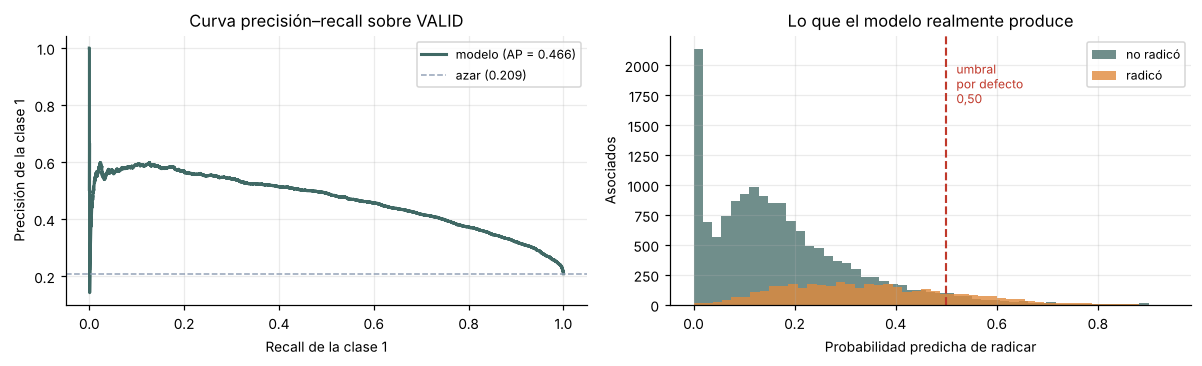

In [15]:
# El modelo elegido se entrena con FIT y el umbral se elige mirando VALID.
# TEST sigue cerrado.
modelo_elegido = construir(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
modelo_elegido.fit(X_fit, y_fit)

prob_valid = modelo_elegido.predict_proba(X_valid)[:, 1]

precisiones, recalls, umbrales = precision_recall_curve(y_valid, prob_valid)
ap_valid = average_precision_score(y_valid, prob_valid)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

axes[0].plot(recalls, precisiones, color=VERDE, lw=2, label=f"modelo (AP = {ap_valid:.3f})")
axes[0].axhline(y_valid.mean(), color=GRIS, ls="--", lw=1,
                label=f"azar ({y_valid.mean():.3f})")
axes[0].set_xlabel("Recall de la clase 1"); axes[0].set_ylabel("Precisión de la clase 1")
axes[0].set_title("Curva precisión–recall sobre VALID"); axes[0].legend(fontsize=8)

axes[1].hist(prob_valid[y_valid == 0], bins=50, color=VERDE, alpha=.75, label="no radicó")
axes[1].hist(prob_valid[y_valid == 1], bins=50, color=NARANJA, alpha=.8, label="radicó")
axes[1].axvline(0.5, color=ROJO, ls="--", lw=1.4)
axes[1].text(0.52, axes[1].get_ylim()[1] * .75, "umbral\npor defecto\n0,50",
             color=ROJO, fontsize=8)
axes[1].set_xlabel("Probabilidad predicha de radicar"); axes[1].set_ylabel("Asociados")
axes[1].set_title("Lo que el modelo realmente produce"); axes[1].legend(fontsize=8)

plt.tight_layout(); plt.show()

In [16]:
# Qué pasa con cada umbral posible (sobre VALID)
rejilla = []
for th in np.arange(0.10, 0.65, 0.05):
    pred = (prob_valid >= th).astype(int)
    rejilla.append({
        "umbral": round(th, 2),
        "asociados marcados": int(pred.sum()),
        "% del total marcado": pred.mean(),
        "recall": recall_score(y_valid, pred),
        "precisión": precision_score(y_valid, pred, zero_division=0),
        "F1": f1_score(y_valid, pred),
    })
rejilla = pd.DataFrame(rejilla)
rejilla.style.format({"% del total marcado": "{:.1%}", "recall": "{:.4f}",
                      "precisión": "{:.4f}", "F1": "{:.4f}",
                      "asociados marcados": "{:,}"}).hide(axis="index")

umbral,asociados marcados,% del total marcado,recall,precisión,F1
0.100000,"13,797",71.2%,0.9552,0.2810,0.4343
0.150000,"10,972",56.6%,0.8889,0.3288,0.4801
0.200000,"8,337",43.0%,0.7810,0.3802,0.5115
0.250000,"6,438",33.2%,0.6785,0.4278,0.5247
0.300000,"4,900",25.3%,0.5642,0.4673,0.5112
0.350000,"3,683",19.0%,0.4558,0.5023,0.4779
0.400000,"2,671",13.8%,0.3447,0.5238,0.4158
0.450000,"1,962",10.1%,0.2668,0.5520,0.3597
0.500000,"1,365",7.0%,0.1919,0.5707,0.2872
0.550000,899,4.6%,0.1301,0.5873,0.2130


In [17]:
# Regla de negocio: detectar al menos el 75% de quienes van a radicar.
RECALL_OBJETIVO = 0.75

candidatos = [(t, recall_score(y_valid, (prob_valid >= t).astype(int)))
              for t in np.arange(0.05, 0.95, 0.001)]
UMBRAL = max(t for t, r in candidatos if r >= RECALL_OBJETIVO)

pred_valid = (prob_valid >= UMBRAL).astype(int)
print(f"Regla de negocio: recall >= {RECALL_OBJETIVO:.0%}")
print(f"Umbral que la cumple con el menor costo en precisión: {UMBRAL:.3f}\n")
print(f"  recall    : {recall_score(y_valid, pred_valid):.4f}")
print(f"  precisión : {precision_score(y_valid, pred_valid):.4f}")
print(f"  F1        : {f1_score(y_valid, pred_valid):.4f}")
print(f"  marcados  : {pred_valid.sum():,} de {len(y_valid):,} asociados "
      f"({pred_valid.mean():.1%})")

Regla de negocio: recall >= 75%
Umbral que la cumple con el menor costo en precisión: 0.216

  recall    : 0.7504
  precisión : 0.3981
  F1        : 0.5202
  marcados  : 7,651 de 19,391 asociados (39.5%)


**Lectura del punto de operación elegido.**

Con el umbral en **0,216** el modelo marca al **39,5 %** de los asociados (7.651 de 19.391),
detecta al **75,0 %** de quienes efectivamente radicaron y acierta en el **39,8 %** de las veces
que marca.

Vale la pena contrastar esos números con lo que significan operativamente. Marcar al 39,5 % para
capturar al 75 % de los casos es, en el fondo, lo que la regla de negocio pedía. Y la precisión
del 39,8 % hay que leerla contra la tasa base: **si la cooperativa contactara asociados al azar,
acertaría el 20,9 %**. El modelo casi duplica esa eficiencia.

Nótese también lo que *no* hicimos: no tocamos el modelo. Es exactamente el mismo que salió del
torneo. Lo único que cambió es dónde pusimos la línea.

### Y una advertencia sobre cómo se reportan estos números

En la tabla de arriba, el mismo modelo pasa de un recall de 0,19 a uno de 0,90 según dónde se
ponga el umbral. **Reportar un recall sin decir con qué umbral se calculó no comunica nada.**
Todas las métricas de este trabajo se reportan con su umbral al lado.

## 12. Una comprobación: `class_weight` y umbral son la misma palanca

Una alternativa habitual para el desbalance es `class_weight`, que obliga al modelo a penalizar
más los errores en la clase minoritaria. Vale la pena verificar si ese camino habría dado algo
distinto del que tomamos, porque la respuesta no es evidente.

In [18]:
# ¿Habría sido mejor ajustar class_weight en vez de mover el umbral?
comprobacion = []
for peso in [None, {0: 1, 1: 2}, {0: 1, 1: 3.88}, "balanced"]:
    pipe = construir(LogisticRegression(class_weight=peso, max_iter=5000,
                                        random_state=RANDOM_STATE))
    cvres = cross_validate(pipe, X_fit, y_fit, cv=cv,
                           scoring={"auc": "roc_auc", "recall": "recall",
                                    "precision": "precision"}, n_jobs=1)
    comprobacion.append({
        "class_weight": str(peso),
        "AUC": cvres["test_auc"].mean(),
        "AUC sd": cvres["test_auc"].std(),
        "recall (umbral 0,50)": cvres["test_recall"].mean(),
        "precisión (umbral 0,50)": cvres["test_precision"].mean(),
    })
pd.DataFrame(comprobacion).round(4)

,class_weight,AUC,AUC sd,"recall (umbral 0,50)","precisión (umbral 0,50)"
0,None,0.7873,0.0022,0.1761,0.5508
1,"{0: 1, 1: 2}",0.7876,0.0022,0.4729,0.4745
2,"{0: 1, 1: 3.88}",0.7874,0.0022,0.7550,0.3861
3,balanced,0.7874,0.0022,0.7453,0.3894


In [19]:
auc_sin = comprobacion[0]["AUC"]
auc_con = comprobacion[2]["AUC"]
print(f"AUC sin class_weight      : {auc_sin:.4f}")
print(f"AUC con class_weight 3,88 : {auc_con:.4f}")
print(f"diferencia                : {abs(auc_con - auc_sin):.4f}  "
      f"(ruido entre folds: {comprobacion[0]['AUC sd']:.4f})")
print()
print(f"Y el umbral {UMBRAL:.2f}, sobre el modelo SIN class_weight, entrega:")
print(f"  recall {recall_score(y_valid, pred_valid):.4f} | "
      f"precisión {precision_score(y_valid, pred_valid):.4f}")

AUC sin class_weight      : 0.7873
AUC con class_weight 3,88 : 0.7874
diferencia                : 0.0002  (ruido entre folds: 0.0022)

Y el umbral 0.22, sobre el modelo SIN class_weight, entrega:
  recall 0.7504 | precisión 0.3981


**El resultado de la comprobación, que es más instructivo de lo que parece.**

Con `class_weight` el AUC pasa de 0,7873 a 0,7874: una diferencia de **0,0002**, contra una
variación entre folds de 0,0022. **El AUC no se movió.** Y no podía moverse: `class_weight`
cambia el peso de los errores durante el ajuste, pero el orden en que el modelo clasifica a los
asociados de mayor a menor riesgo permanece prácticamente idéntico. Lo que cambia es dónde queda
el corte efectivo.

Compárense los dos caminos en el punto de operación que nos interesa:

| Camino | Recall | Precisión |
|---|---|---|
| `class_weight = {0: 1, 1: 3,88}`, umbral 0,50 | 0,7550 | 0,3861 |
| sin `class_weight`, umbral 0,216 | 0,7504 | 0,3981 |

Prácticamente el mismo punto. **Son dos formas de hacer lo mismo**, y la del umbral tiene dos
ventajas prácticas: no requiere reentrenar nada para explorar alternativas, y hace la decisión
explícita y reversible —el umbral es un número en un archivo de configuración, no un
hiperparámetro enterrado en el modelo—.

> **Nota metodológica.** En una versión anterior de este trabajo, el peso de la clase minoritaria
> se buscó con cien iteraciones de Optuna hasta alcanzar un recall de 0,75. El resultado fue un
> peso de 3,88, que es el de la primera fila. Comprobar que ese mismo punto se alcanza moviendo
> un umbral es, en sí mismo, un hallazgo: **no todo lo que se puede optimizar hace falta
> optimizarlo.** Optuna es la herramienta correcta cuando el espacio de búsqueda es grande y los
> hiperparámetros interactúan; aquí el espacio era una sola palanca monótona.

## 13. Evaluación final sobre el conjunto de prueba

Hasta este punto, el conjunto de prueba no ha participado en nada: ni en el entrenamiento, ni en
la comparación de modelos, ni en la elección del umbral. Ahora se abre, **una sola vez**, para
medir lo que el modelo hará con asociados que nunca vio.

El modelo se reentrena con `fit + valid` —todo lo que no es prueba— conservando el umbral 0,216
fijado en la sección anterior.

In [20]:
# Se reentrena con FIT + VALID (todo lo que no es test) y se evalúa UNA vez.
X_entrenamiento = pd.concat([X_fit, X_valid])
y_entrenamiento = pd.concat([y_fit, y_valid])

modelo_final = construir(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
modelo_final.fit(X_entrenamiento, y_entrenamiento)

prob_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = (prob_test >= UMBRAL).astype(int)

resumen = pd.DataFrame({
    "métrica": ["AUC-ROC", "Promedio de precisión (AP)", "Recall clase 1",
                "Precisión clase 1", "F1 clase 1"],
    "validación": [roc_auc_score(y_valid, prob_valid),
                   average_precision_score(y_valid, prob_valid),
                   recall_score(y_valid, pred_valid),
                   precision_score(y_valid, pred_valid),
                   f1_score(y_valid, pred_valid)],
    "prueba": [roc_auc_score(y_test, prob_test),
               average_precision_score(y_test, prob_test),
               recall_score(y_test, pred_test),
               precision_score(y_test, pred_test),
               f1_score(y_test, pred_test)],
})
resumen["diferencia"] = resumen["prueba"] - resumen["validación"]
resumen["ruido típico (sd entre folds)"] = [
    torneo.loc[torneo["modelo"] == "Regresión Logística", c].iloc[0]
    for c in ["auc_sd", "ap_sd", "recall_1_sd", "precision_1_sd", "f1_1_sd"]]
resumen.round(4)

,métrica,validación,prueba,diferencia,ruido típico (sd entre folds)
0,AUC-ROC,0.7947,0.7895,-0.0052,0.0022
1,Promedio de precisión (AP),0.4664,0.4528,-0.0136,0.0041
2,Recall clase 1,0.7504,0.7494,-0.0010,0.0044
3,Precisión clase 1,0.3981,0.3962,-0.0019,0.0071
4,F1 clase 1,0.5202,0.5184,-0.0018,0.0056


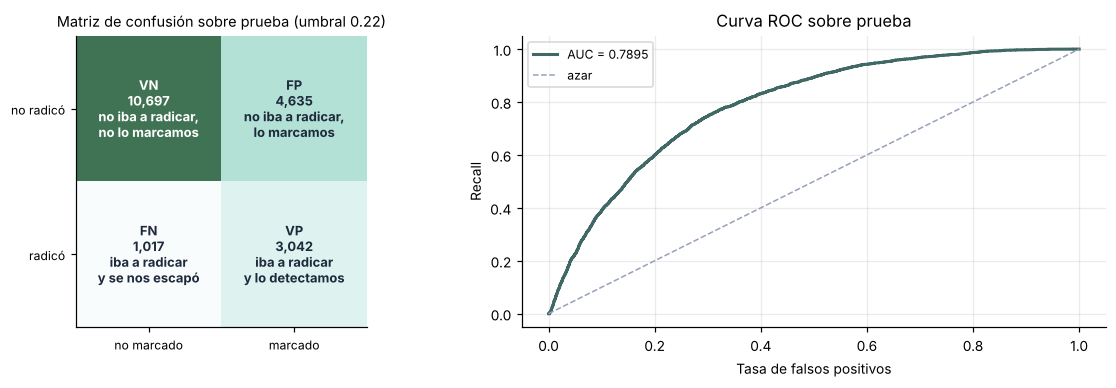

              precision    recall  f1-score   support

   No radica     0.9132    0.6977    0.7910     15332
      Radica     0.3962    0.7494    0.5184      4059

    accuracy                         0.7085     19391
   macro avg     0.6547    0.7236    0.6547     19391
weighted avg     0.8050    0.7085    0.7340     19391



In [21]:
cm = confusion_matrix(y_test, pred_test)
vn, fp, fn, vp = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

ax = axes[0]; ax.grid(False)
ax.imshow(cm, cmap="BuGn", alpha=.75)
etiquetas = [[f"VN\n{vn:,}\nno iba a radicar,\nno lo marcamos",
              f"FP\n{fp:,}\nno iba a radicar,\nlo marcamos"],
             [f"FN\n{fn:,}\niba a radicar\ny se nos escapó",
              f"VP\n{vp:,}\niba a radicar\ny lo detectamos"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, etiquetas[i][j], ha="center", va="center", fontsize=8.5,
                color="white" if cm[i, j] > cm.max() / 2 else "#1e293b", weight="bold")
ax.set_xticks([0, 1]); ax.set_xticklabels(["no marcado", "marcado"], fontsize=8)
ax.set_yticks([0, 1]); ax.set_yticklabels(["no radicó", "radicó"], fontsize=8)
ax.set_title(f"Matriz de confusión sobre prueba (umbral {UMBRAL:.2f})", fontsize=9.5)

ax = axes[1]
fpr, tpr, _ = roc_curve(y_test, prob_test)
ax.plot(fpr, tpr, color=VERDE, lw=2, label=f"AUC = {roc_auc_score(y_test, prob_test):.4f}")
ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1, label="azar")
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Recall")
ax.set_title("Curva ROC sobre prueba"); ax.legend(fontsize=8)

plt.tight_layout(); plt.show()

print(classification_report(y_test, pred_test,
                            target_names=["No radica", "Radica"], digits=4))

**Lectura de la evaluación final.**

La columna de la derecha es la que da sentido a toda la tabla: cada diferencia entre validación y
prueba se compara contra la variación típica entre folds observada durante el torneo.

- **El recall, que es la métrica que importa para la regla de negocio, cayó 0,0010** (de 0,7504 a
  0,7494), contra un ruido entre folds de 0,0044. La diferencia es **cuatro veces más pequeña que
  el ruido**: el punto de operación se sostuvo. La regla de detectar al 75 % se cumple también
  sobre datos nunca vistos.
- **La precisión y el F1 se comportan igual**: diferencias de 0,002, muy por debajo de su propio
  ruido.
- **El AUC y el AP caen un poco más** (0,0052 y 0,0136) de lo que explica el ruido entre folds.
  Conviene no sobreinterpretarlo: ese ruido se midió sobre folds de 31.000 registros, mientras que
  validación y prueba tienen 19.391 cada uno. Con muestras más pequeñas, variaciones de ese orden
  son esperables. Lo que sí se puede afirmar es que **no hay un desplome**: el modelo generaliza.

**Qué dice la matriz de confusión en términos de la cooperativa.** De los 4.059 asociados que
efectivamente radicaron solicitud, el modelo detectó 3.042 y se le escaparon 1.017. Para lograrlo
marcó también a 4.637 asociados que no pensaban irse. Dicho en la lógica de la sección 8.2: se
evitó perder de vista a tres de cada cuatro asociados en riesgo, al precio de 4.637 acciones de
fidelización dirigidas a personas que no las necesitaban.

**Y la exactitud, por última vez.** El reporte muestra 0,7085, *por debajo* del 0,7908 que sacaría
un modelo que nunca detecta a nadie. Esa comparación es precisamente la razón por la cual la
exactitud no se usó como criterio: el modelo es peor en exactitud y mucho mejor para el problema
que se quiere resolver.

## 14. Explicabilidad

### 14.1 Los coeficientes del modelo

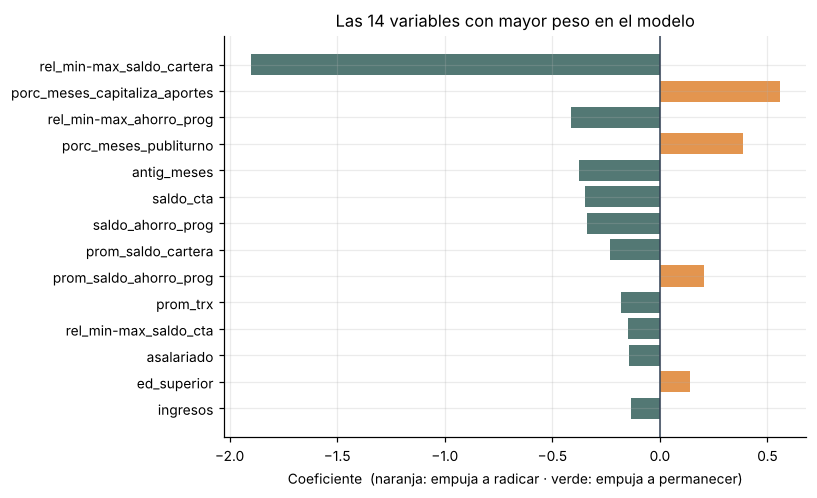

,variable,coeficiente,razón de momios
0,rel_min-max_saldo_cartera,-1.9024,0.1492
1,porc_meses_capitaliza_aportes,0.5575,1.7462
2,rel_min-max_ahorro_prog,-0.4110,0.6630
3,porc_meses_publiturno,0.3884,1.4747
4,antig_meses,-0.3760,0.6866
5,saldo_cta,-0.3460,0.7075
6,saldo_ahorro_prog,-0.3394,0.7122
7,prom_saldo_cartera,-0.2316,0.7933
8,prom_saldo_ahorro_prog,0.2037,1.2260
9,prom_trx,-0.1827,0.8330


In [22]:
coef = modelo_final.named_steps["modelo"].coef_[0]
importancia = (pd.DataFrame({
        "variable": X.columns,
        "coeficiente": coef,
        "razón de momios": np.exp(coef),
    })
    .assign(magnitud=lambda d: d["coeficiente"].abs())
    .sort_values("magnitud", ascending=False)
    .drop(columns="magnitud")
    .reset_index(drop=True))

fig, ax = plt.subplots(figsize=(7.5, 4.6))
top = importancia.head(14).iloc[::-1]
colores = [NARANJA if c > 0 else VERDE for c in top["coeficiente"]]
ax.barh(top["variable"], top["coeficiente"], color=colores, alpha=.9)
ax.axvline(0, color="#334155", lw=1)
ax.set_xlabel("Coeficiente  (naranja: empuja a radicar · verde: empuja a permanecer)")
ax.set_title("Las 14 variables con mayor peso en el modelo")
plt.tight_layout(); plt.show()

importancia.head(14).round(4)

**Cómo se leen estos coeficientes.** El modelo trabaja sobre variables estandarizadas, así que
cada coeficiente expresa cuánto cambia el logaritmo de las probabilidades relativas de radicar
cuando esa variable sube una desviación estándar, con las demás constantes. La razón de momios es
ese mismo efecto en una escala más intuitiva: por encima de 1 empuja a radicar, por debajo de 1
empuja a permanecer.

**Lo que más pesa, con diferencia, es `rel_min-max_saldo_cartera`** (coeficiente −1,90, razón de
momios 0,15). Un asociado con una relación alta entre su saldo mínimo y máximo de cartera tiene
una vida crediticia sostenida con la cooperativa, y eso se asocia fuertemente con permanecer. Es
coherente con lo que se observa en la operación: **el crédito ata, los aportes sueltos no.**

**En sentido contrario, `porc_meses_capitaliza_aportes`** (razón de momios 1,75) y
`porc_meses_publiturno` (1,47) empujan hacia la radicación. Este resultado merece atención porque
es contraintuitivo a primera vista: quien más capitaliza aportes y más visita las agencias es
quien más tiende a solicitar el retiro. La lectura que proponemos es que esos asociados
**conciben los aportes sociales como un ahorro disponible** más que como el vínculo con la
cooperativa, y la visita frecuente a la agencia es parte de esa relación transaccional.

> ⚠️ **Advertencia necesaria.** Esto es **asociación, no causalidad**. Que capitalizar aportes se
> asocie con radicar no significa que convenga desincentivar la capitalización: significa que ese
> perfil merece una conversación distinta sobre el sentido de los aportes.

### 14.2 Valores SHAP

Los coeficientes ya explican el modelo, porque es lineal. Añadimos SHAP por una razón distinta:
muestra, para **cada asociado individual**, cuánto empujó cada variable su probabilidad concreta.
Eso es lo que permite pasar de "el modelo marcó a esta persona" a "el modelo la marcó por esto",
que es lo que un asesor necesita para preparar un contacto.

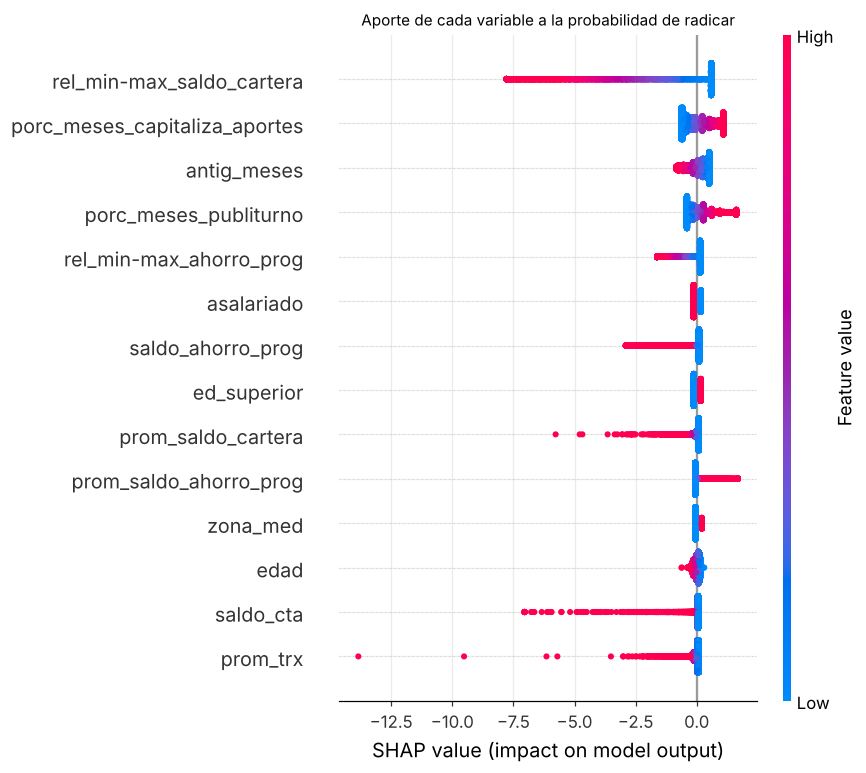

In [23]:
# El 'background' sale del conjunto de ENTRENAMIENTO, nunca de test:
# usar test como referencia sería dejar que el conjunto reservado
# influya en la explicación del modelo.
escalador = modelo_final.named_steps["escalar"]
logistica = modelo_final.named_steps["modelo"]

fondo = pd.DataFrame(escalador.transform(X_entrenamiento.sample(1000, random_state=RANDOM_STATE)),
                     columns=X.columns)
X_test_esc = pd.DataFrame(escalador.transform(X_test), columns=X.columns, index=X_test.index)

explicador = shap.LinearExplainer(logistica, shap.maskers.Independent(fondo, max_samples=1000))
valores_shap = explicador(X_test_esc)

shap.summary_plot(valores_shap, X_test_esc, max_display=14, show=False)
plt.title("Aporte de cada variable a la probabilidad de radicar", fontsize=10)
plt.tight_layout(); plt.show()

En el gráfico, cada punto es un asociado del conjunto de prueba. La posición horizontal indica
cuánto empujó esa variable su predicción (a la derecha, hacia radicar) y el color indica si el
valor de la variable era alto o bajo. El patrón confirma lo que mostraban los coeficientes, y
añade un matiz: para la mayoría de los asociados el aporte de cada variable es pequeño, y son
unos pocos casos los que reciben empujones grandes. Es decir, **el modelo no aplica una regla
uniforme: reacciona a perfiles concretos.**

## 15. Conclusiones

### 15.1 Qué se logró

**Modelar aporta sobre no modelar, con un margen enorme.** El baseline no detecta a un solo
asociado de los que radican. El modelo desplegado detecta a tres de cada cuatro.

**El modelo generaliza.** En el punto de operación elegido, el recall pasó de 0,7504 en
validación a 0,7494 en prueba: una diferencia cuatro veces menor que la variación entre folds.
La regla de negocio se cumple sobre datos nunca vistos.

**La afinación del desbalance no mejora el modelo: lo reposiciona.** Quedó demostrado que
`class_weight` deja el AUC intacto (0,7873 → 0,7874, frente a un ruido de 0,0022) y que el mismo
punto de operación se alcanza moviendo el umbral. Es un canje entre recall y precisión, no una
ganancia de capacidad, y nombrarlo correctamente importa.

**Los factores de permanencia tienen una lectura de negocio clara.** Una vida crediticia
sostenida con la cooperativa es, con diferencia, el factor más asociado a permanecer. En sentido
contrario, el perfil que capitaliza aportes con frecuencia y visita mucho las agencias es el que
más tiende a radicar: son asociados que leen sus aportes como un ahorro disponible.

### 15.2 Limitaciones

**1. El modelo desplegado no es el más preciso disponible, y eso tiene un costo medido.** Random
Forest supera a la Regresión Logística por 0,107 de AUC y por 0,25 de promedio de precisión —una
distancia de decenas de veces la variación entre folds, no un empate—. Elegimos explicabilidad y
auditabilidad sobre rendimiento, y la sección 10 cuantifica lo que esa decisión cuesta en
contactos innecesarios.

**2. Los datos son una fotografía histórica cerrada.** El dataset recoge asociados vinculados
entre 2017 y 2025, con un registro por persona. El modelo no está diseñado para quienes ingresaron
antes de 2017 —no se tiene su historia completa— ni incorpora el comportamiento posterior al
corte. Si las condiciones del mercado o las políticas de la cooperativa cambian, el modelo
envejece sin avisar.

**3. Un registro por asociado elimina la dimensión temporal.** Las variables resumen todo el
historial en promedios y porcentajes, de modo que el modelo no distingue entre un deterioro
reciente y uno antiguo. Dos asociados con el mismo promedio de transacciones le resultan
idénticos, aunque uno venga cayendo y el otro recuperándose.

**4. El modelo describe asociaciones, no causas.** Ninguna de las relaciones de la sección 14
autoriza a concluir que modificar una variable modificaría la decisión del asociado.

### 15.3 Qué puede hacer Confiar con esto

**Acción inmediata: un piloto con grupo de control.** Tomar la lista de asociados marcados por el
modelo en el próximo corte, dividirla al azar en dos, intervenir solo una mitad y medir a tres
meses la diferencia en radicaciones entre ambos grupos. Es la única forma de pasar de "estos
asociados están en riesgo" a "intervenir reduce el riesgo", que es lo que el modelo por sí solo
no puede demostrar.

**Dos decisiones que el piloto permitiría tomar después:**

- **Calibrar el umbral contra la capacidad real.** El 0,216 sale de una regla de negocio fijada a
  priori. Con el costo real de un contacto y el valor promedio de los aportes de un asociado, el
  umbral puede recalcularse para maximizar el beneficio esperado en vez de un porcentaje elegido.
- **Reevaluar el modelo elegido.** Si el piloto muestra que el volumen de falsas alarmas satura al
  equipo, la diferencia de rendimiento con Random Forest deja de ser un costo aceptable y conviene
  migrar, acompañando el cambio con SHAP para conservar la explicabilidad.

**Y una recomendación de gestión del modelo:** recalibrar cada seis meses con datos nuevos y
vigilar la estabilidad del recall. Un modelo de churn envejece con el comportamiento que
describe.